# A Star
From AA274A Homework 1

In [1]:
%load_ext autoreload
%autoreload 2

In [19]:
import matplotlib.pyplot as plt
import numpy as np

from cesium.planning import AStarGrid, AStarHeuristic, generate_planning_problem, StaticOccupancyGrid2D, smooth_path, path_length

## Sanity Checks

Quick checks of `distance`, `heuristic`, and `get_neighbors` (implement `is_free` and `heuristic` as well before running this cell, since the `AStar` constructor calls `heuristic`). These are not exhaustive, but every assertion should pass before you move on.

In [3]:
_empty = StaticOccupancyGrid2D(10, 10, [])
_a = AStarGrid((0, 10), (0, 10), (1, 1), (4, 5), _empty)
assert np.isclose(_a.distance((1, 1), (4, 5)), 5.0)

for _h, _expected in [(AStarHeuristic.l1, 7.0), (AStarHeuristic.l2, 5.0), (AStarHeuristic.linf, 4.0)]:
    _a = AStarGrid((0, 10), (0, 10), (1, 1), (4, 5), _empty, heuristic=_h)
    assert np.isclose(_a.heuristic((1, 1)), _expected), _h
    assert np.isclose(_a.distance((1, 1), (4, 5)), 5.0), "distance must not depend on the heuristic"

_a = AStarGrid((0, 10), (0, 10), (1, 1), (4, 5), _empty, heuristic_weight=2.0)
assert np.isclose(_a.heuristic((1, 1)), 10.0)

assert len(_a.get_neighbors((5, 5))) == 8
assert len(_a.get_neighbors((0, 0))) == 3
print("All sanity checks passed!")

All sanity checks passed!


## Problem

In [4]:
width = 10
height = 10
obstacles = [((0,3),(6,4)),((4,6),(10,7)),((7,0),(8,2)),((1,8),(3,9)),((8,4),(9,5))]
occupancy = StaticOccupancyGrid2D(width, height, obstacles)

x_init = (1, 1)
x_goal = (9, 9)

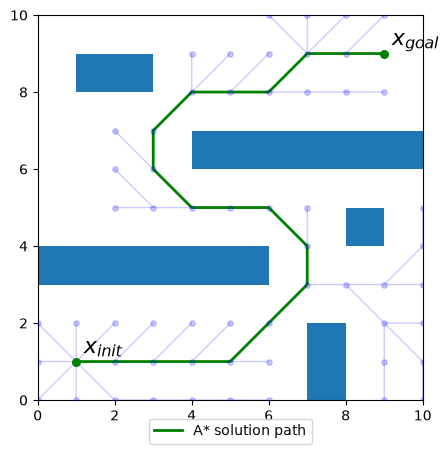

In [6]:
astar = AStarGrid((0, width), (0, height), x_init, x_goal, occupancy)
if not astar.solve():
    print("No path found")
else:
    plt.rcParams['figure.figsize'] = [5, 5]
    astar.plot_path()
    astar.plot_tree()

## Random Environment

In [8]:
SEED = 274  # use 274 for the plots in your write-up
np.random.seed(SEED)

width = 10
height = 10
num_obs = 25
min_size = .5
max_size = 3

occupancy, x_init, x_goal = generate_planning_problem(width, height, num_obs, min_size, max_size)

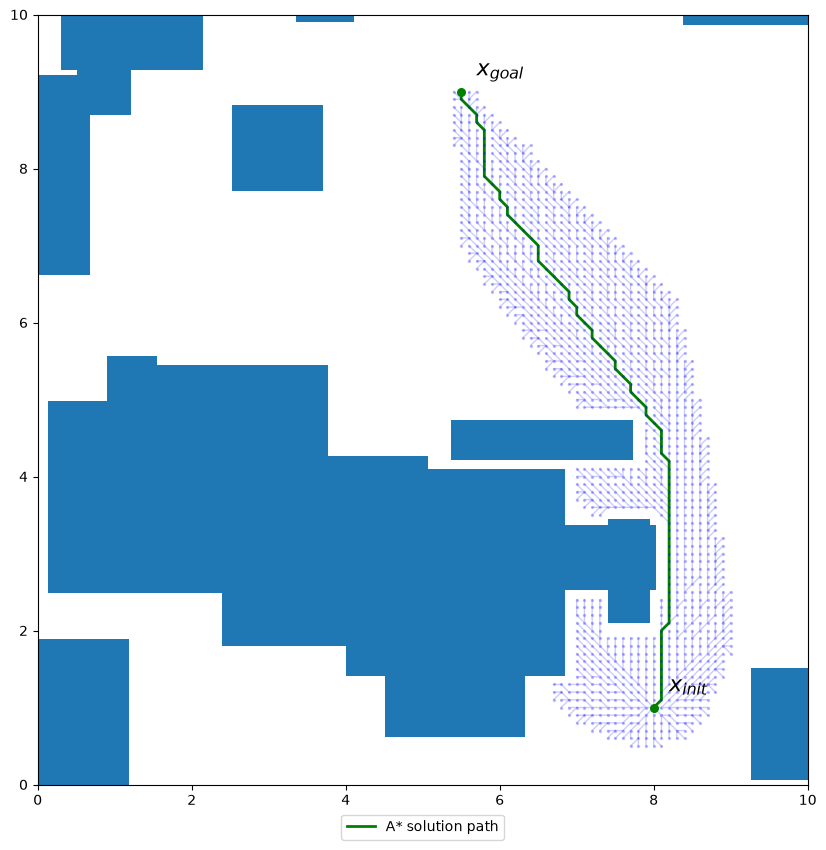

In [9]:
astar = AStarGrid((0, width), (0, height), x_init, x_goal, occupancy, resolution=0.1)
if not astar.solve():
    print("No path found! (This is normal, try re-running the block above)")
else:
    plt.rcParams['figure.figsize'] = [10, 10]
    astar.plot_path()
    astar.plot_tree(point_size=2)

## Smoothing

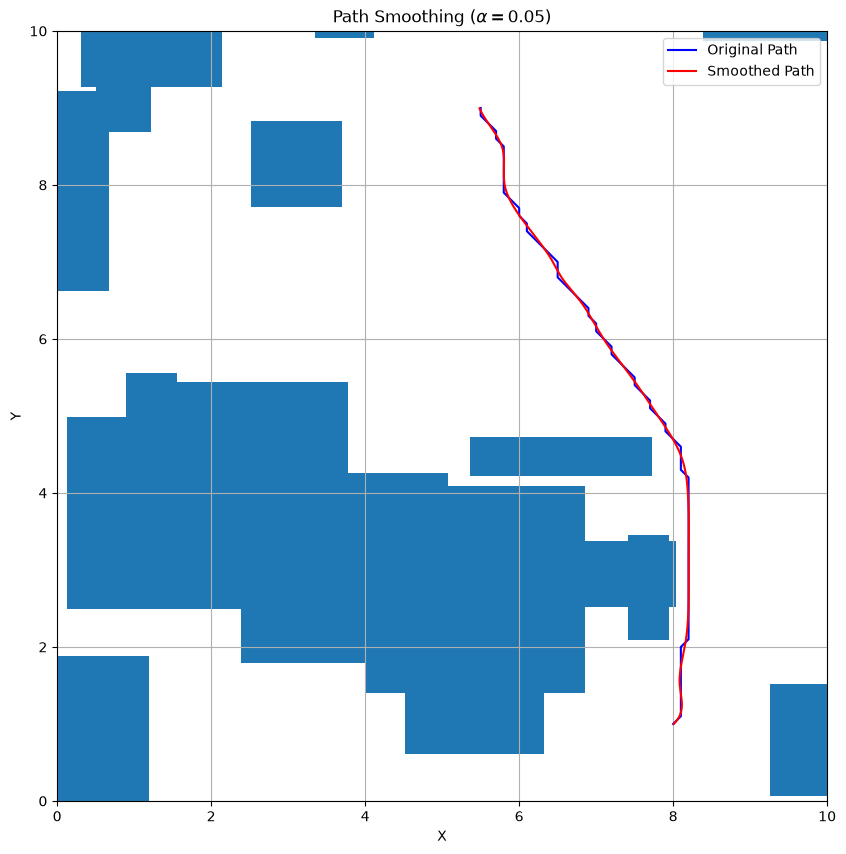

In [15]:
# construct a trajectory plan (0.05)
plan = smooth_path(astar.path, v_desired=0.15,spline_alpha=0.05)

# plot AStar path v.s. smoothed path
astar_path = np.asarray(astar.path)
smoothed_path = plan.smoothed_path()

astar.grid.plot() # Added

plt.plot(astar_path[:,0], astar_path[:,1], 'b-', label='Original Path')
plt.plot(smoothed_path[:, 0], smoothed_path[:, 1], 'r-', label='Smoothed Path')
plt.legend()
plt.xlabel('X')
plt.ylabel('Y')
plt.xlim([0, width])
plt.ylim([0, height])
plt.title(r'Path Smoothing ($\alpha = 0.05$)')
plt.grid()

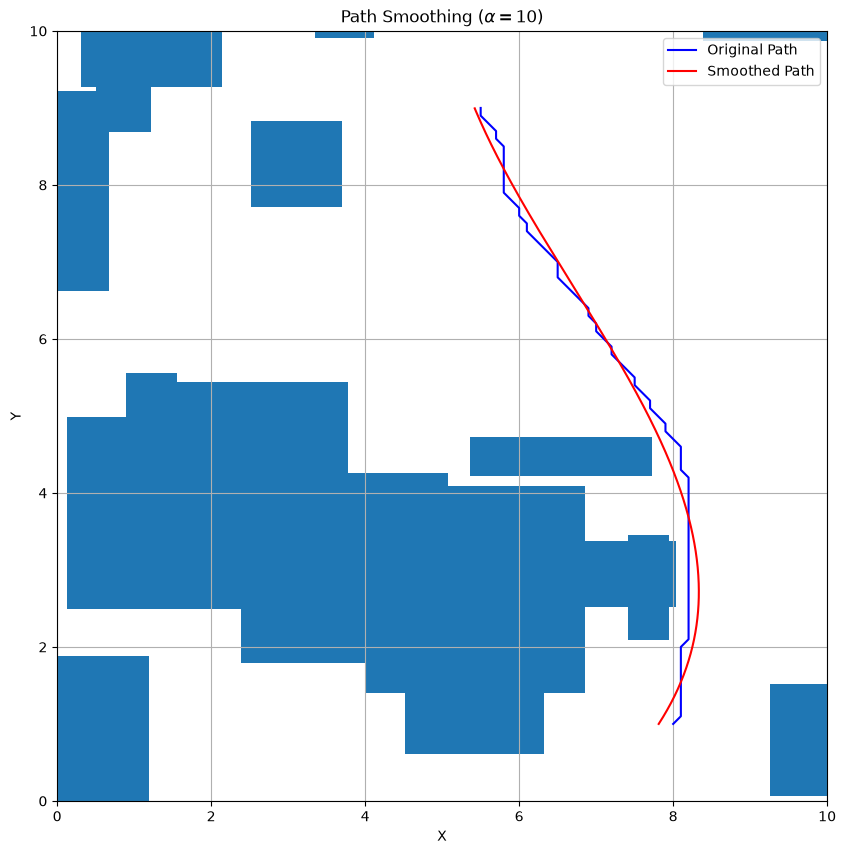

In [17]:
# construct a trajectory plan (10)
plan = smooth_path(astar.path, spline_alpha=10)

# plot AStar path v.s. smoothed path
astar_path = np.asarray(astar.path)
smoothed_path = plan.smoothed_path()

astar.grid.plot() # Added

plt.plot(astar_path[:,0], astar_path[:,1], 'b-', label='Original Path')
plt.plot(smoothed_path[:, 0], smoothed_path[:, 1], 'r-', label='Smoothed Path')
plt.legend()
plt.xlabel('X')
plt.ylabel('Y')
plt.xlim([0, width])
plt.ylim([0, height])
plt.title(r'Path Smoothing ($\alpha = 10$)')
plt.grid()

# Heuristic Comparison

heuristic |    w | path length | nodes expanded
-------------------------------------------------
       l2 |  1.0 |       9.201 |           1091 | 9.201219330881964
       l1 |  1.0 |       9.201 |            318 | 9.201219330881973
     linf |  1.0 |       9.201 |           1965 | 9.201219330881965
       l2 |  3.0 |       9.898 |            146 | 9.898275605729687


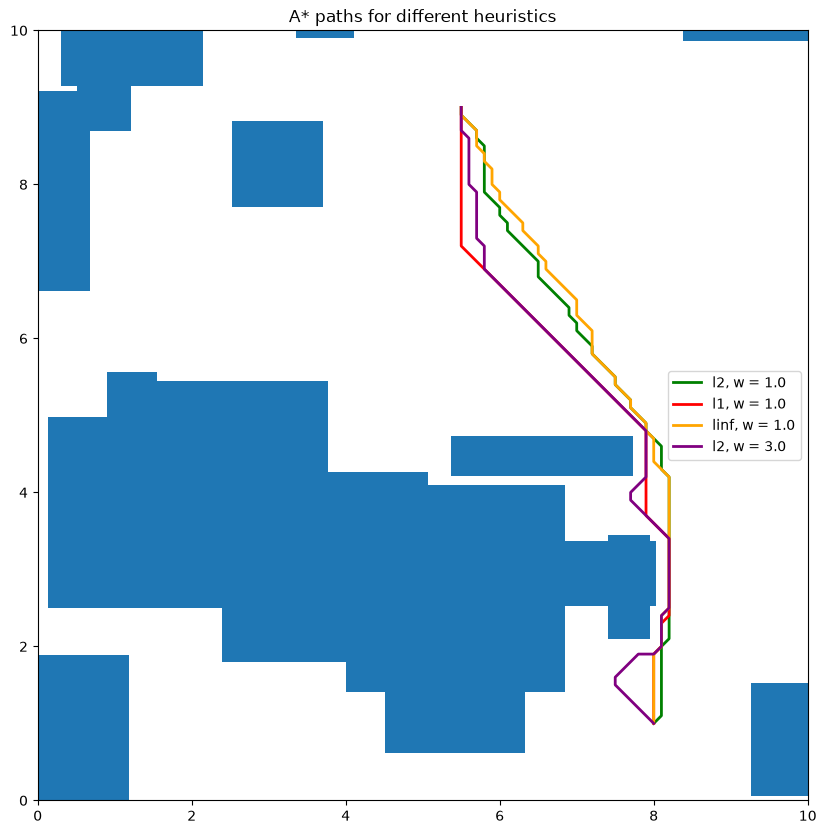

In [26]:
configs = [(AStarHeuristic.l2, 1.0), (AStarHeuristic.l1, 1.0), (AStarHeuristic.linf, 1.0), (AStarHeuristic.l2, 3.0)]
colors = ["green", "red", "orange", "purple"]

plt.rcParams['figure.figsize'] = [10, 10]
occupancy.plot()
print(f"{'heuristic':>9} | {'w':>4} | {'path length':>11} | {'nodes expanded':>14}")
print("-" * 49)
for (heuristic, weight), color in zip(configs, colors):
    astar_h = AStarGrid((0, width), (0, height), x_init, x_goal, occupancy, resolution=0.1,
                    heuristic=heuristic, heuristic_weight=weight)
    if not astar_h.solve():
        print(f"{heuristic:>9} | {weight:>4.1f} | no path found")
        continue
    print(f"{heuristic.name:>9} | {weight:>4.1f} | {path_length(astar_h.path):>11.3f} | {len(astar_h.visited):>14d} | {astar_h.cost_to_arrive[astar_h.x_goal]}")
    p = np.asarray(astar_h.path)
    plt.plot(p[:, 0], p[:, 1], color=color, linewidth=2, label=f"{heuristic.name}, w = {weight}")
plt.legend()
plt.title("A* paths for different heuristics")
plt.show()